# Componentes principales: geometría, reducción de dimensión y dígitos escritos a mano

Cuaderno **complementario del Capítulo 2** de las notas. El cuaderno ★ `PCA_Paises.ipynb` reproduce los ejemplos del capítulo; éste agrega dos ejemplos: una nube de puntos en dos dimensiones, para ver la geometría del PCA, y 1797 imágenes de dígitos escritos a mano de 8 × 8 píxeles, un caso en el que **no** conviene estandarizar.

> **Fuente del código.** Los dos ejemplos y parte del código siguen la sección *In Depth: Principal Component Analysis* de J. VanderPlas (2016), *Python Data Science Handbook*, O'Reilly Media (https://github.com/jakevdp/PythonDataScienceHandbook). Ese código se distribuye con licencia MIT y se conserva la atribución a su autor. El texto de este cuaderno es original. Los dígitos vienen incluidos en `sklearn` (`load_digits`, una copia de la base *Optical Recognition of Handwritten Digits* del repositorio UCI).

**Contenido**
1. Una nube de puntos en dos dimensiones
2. Los ejes principales
3. Reducir a una dimensión y reconstruir
4. Dígitos escritos a mano: ¿estandarizar o no?
5. Los dígitos en dos dimensiones
6. ¿Cuántos componentes?
7. Error común: estandarizar los píxeles
8. Reconstruir los dígitos con $k$ componentes
9. Autoevaluación
10. Ejercicio para el alumno

**Cómo usar este cuaderno.** Después de los resultados principales hay celdas **Lea la salida** con espacios `____` para completar, con el mismo formato que el quiz y el examen. Complételas *antes* de abrir la respuesta. La celda **Error común** muestra a propósito un análisis equivocado. Al final hay una autoevaluación.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_digits

## 1. Una nube de puntos en dos dimensiones

200 puntos simulados con dos variables correlacionadas, $x_1$ y $x_2$, medidas en las mismas unidades.

Varianzas (divisor n): [0.679 0.098]
Correlación: 0.889


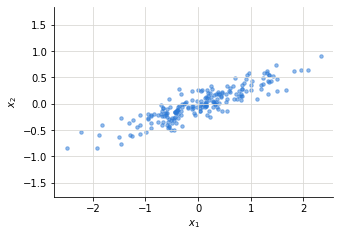

In [2]:
rng = np.random.RandomState(1)
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
n = len(X)
print("Varianzas (divisor n):", X.var(axis=0).round(4))
print("Correlación:", np.corrcoef(X.T)[0, 1].round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(X[:, 0], X[:, 1], s=12, color=AZUL, alpha=0.5)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.axis("equal"); plt.show()

## 2. Los ejes principales

`PCA` centra los datos y calcula los eigenvectores de la matriz de covarianzas. Aquí no se estandariza, porque las dos variables están en las mismas unidades. Las flechas parten de la media y miden tres desviaciones estándar en la dirección de cada componente.

components_ (una fila por componente):
 [[ 0.945  0.329]
 [-0.329  0.945]]
explained_variance_ (divisor n-1): [0.762 0.018]
explained_variance_ratio_: [0.976 0.024]
Eigenvalores de S (divisor n): [0.759 0.018]


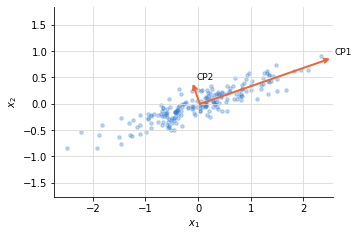

In [3]:
pca = PCA().fit(X)
print("components_ (una fila por componente):\n", pca.components_.round(4))
print("explained_variance_ (divisor n-1):", pca.explained_variance_.round(4))
print("explained_variance_ratio_:", pca.explained_variance_ratio_.round(4))
print("Eigenvalores de S (divisor n):", np.linalg.eigvalsh(np.cov(X.T, ddof=0))[::-1].round(4))


def flecha(ax, origen, destino):
    ax.annotate("", destino, origen, arrowprops=dict(arrowstyle="->", lw=2, color=NARANJA, shrinkA=0, shrinkB=0))


fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(X[:, 0], X[:, 1], s=12, color=AZUL, alpha=0.3)
for k, (lam, g) in enumerate(zip(pca.explained_variance_, pca.components_), start=1):
    v = g * 3 * np.sqrt(lam)
    flecha(ax, pca.mean_, pca.mean_ + v)
    ax.annotate(f"CP{k}", pca.mean_ + v, xytext=(4, 4), textcoords="offset points", fontsize=9, color=TINTA)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.axis("equal"); plt.show()

### Lea la salida

1. La primera fila de `components_`, $(0.945, 0.329)$, es la dirección de `____`; la segunda es `____` (paralela / perpendicular) a ella.
2. El CP1 explica `____` % de la varianza. Su flecha es más larga porque `____`.
3. `explained_variance_` y los eigenvalores de $\mathbf{S}$ difieren en el factor `____`; las proporciones `____` (cambian / no cambian).

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. La dirección de máxima varianza: el eje largo de la nube. La segunda es perpendicular, porque los eigenvectores de una matriz simétrica son ortogonales.
2. 97.6 %. La longitud de la flecha es proporcional a la desviación estándar $\sqrt{\lambda}$: $\sqrt{0.762} \approx 0.87$ contra $\sqrt{0.018} \approx 0.14$.
3. $n/(n-1) = 200/199$ (por ejemplo, $0.759 \times 200/199 = 0.762$). Las proporciones no cambian, porque el factor es común a todos los eigenvalores.

</details>

## 3. Reducir a una dimensión y reconstruir

Con `n_components=1` cada punto se resume con un solo número: su puntuación en el CP1. `inverse_transform` regresa ese número al plano, y el punto reconstruido es la proyección del original sobre la recta del CP1.

Forma original: (200, 2) | reducida: (200, 1) | reconstruida: (200, 2)
Error cuadrático medio de reconstrucción (divisor n): 0.0184
Segundo eigenvalor de S (divisor n): 0.0184
Fracción de la varianza total que se pierde: 0.0237


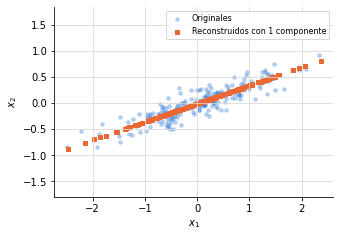

In [4]:
pca1 = PCA(n_components=1).fit(X)
y1 = pca1.transform(X)                 # 200 x 1
X_rec = pca1.inverse_transform(y1)     # 200 x 2, sobre la recta del CP1
print("Forma original:", X.shape, "| reducida:", y1.shape, "| reconstruida:", X_rec.shape)
err = ((X - X_rec) ** 2).sum(axis=1)
print("Error cuadrático medio de reconstrucción (divisor n):", err.mean().round(4))
print("Segundo eigenvalor de S (divisor n):", np.linalg.eigvalsh(np.cov(X.T, ddof=0))[0].round(4))
print("Fracción de la varianza total que se pierde:", (err.sum() / ((X - X.mean(axis=0)) ** 2).sum()).round(4))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(X[:, 0], X[:, 1], s=12, color=AZUL, alpha=0.3, label="Originales")
ax.scatter(X_rec[:, 0], X_rec[:, 1], s=12, color=NARANJA, marker="s", label="Reconstruidos con 1 componente")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.axis("equal"); ax.legend(fontsize=8); plt.show()

### Lea la salida

1. El error cuadrático medio de reconstrucción es `____`, igual a `____`.
2. La fracción de la varianza que se pierde es `____` %, que coincide con `____` de la sección 2.
3. ¿Qué resultado del capítulo 2 garantiza que ninguna otra recta da un error menor? `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 0.0184, igual al segundo eigenvalor de $\mathbf{S}$ (con divisor $n$).
2. 2.37 %, la proporción explicada por el CP2 (`explained_variance_ratio_[1]`).
3. El teorema de Pearson, caso particular del de Eckart–Young: la recta del CP1 minimiza la suma de distancias al cuadrado. Como la varianza total es fija, maximizar la varianza capturada (Hotelling) equivale a minimizar la perdida (Pearson).

</details>

## 4. Dígitos escritos a mano: ¿estandarizar o no?

`load_digits` contiene 1797 imágenes de 8 × 8 píxeles. Cada imagen es una fila con 64 variables: la intensidad de cada píxel, de 0 (blanco) a 16 (negro).

Forma: (1797, 64) | valores de 0.0 a 16.0


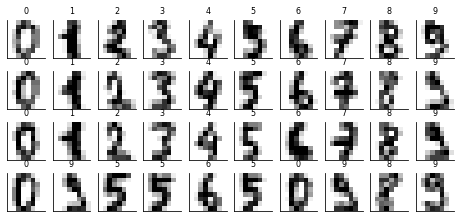

In [5]:
digitos = load_digits()
D, etiqueta = digitos.data, digitos.target
print("Forma:", D.shape, "| valores de", D.min(), "a", D.max())

fig, axes = plt.subplots(4, 10, figsize=(8, 3.6), subplot_kw={"xticks": [], "yticks": []})
for i, ax in enumerate(axes.flat):
    ax.imshow(digitos.images[i], cmap="binary", clim=(0, 16))
    ax.set_title(etiqueta[i], fontsize=8)
    ax.grid(False)
plt.show()

Píxeles con varianza 0: 3 | con varianza menor que 0.1: 11
Varianza mínima distinta de 0: 0.0006 | máxima: 42.7


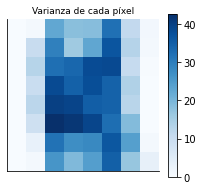

In [6]:
var_px = D.var(axis=0)
print("Píxeles con varianza 0:", (var_px == 0).sum(), "| con varianza menor que 0.1:", (var_px < 0.1).sum())
print("Varianza mínima distinta de 0:", var_px[var_px > 0].min().round(4), "| máxima:", var_px.max().round(1))

fig, ax = plt.subplots(figsize=(3.4, 3))
im = ax.imshow(var_px.reshape(8, 8), cmap="Blues")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title("Varianza de cada píxel", fontsize=9)
plt.colorbar(im, ax=ax); plt.show()

### Lea la salida

1. Las 64 variables están en `____` (las mismas / distintas) unidades.
2. Los píxeles con varianza casi nula están en `____` de la imagen, porque `____`.
3. Por eso aquí conviene hacer el PCA con `____` ($\mathbf{S}$ / $\mathbf{R}$): un píxel que varía mucho `____` (debe / no debe) pesar más que uno que casi nunca cambia.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. Las mismas: intensidad de 0 a 16.
2. En los bordes, sobre todo el izquierdo y el derecho: ahí casi siempre hay blanco. Tres píxeles nunca cambian.
3. Con $\mathbf{S}$. Un píxel que varía mucho debe pesar más, porque su variación es información real sobre la forma del dígito. Es el caso opuesto a `PCA_Paises`, donde las variables tenían unidades distintas (dólares, tasas, porcentajes) y por eso se usaba $\mathbf{R}$.

</details>

## 5. Los dígitos en dos dimensiones

Proyectamos las 64 dimensiones sobre los dos primeros componentes. Para que la gráfica se pueda leer, se destacan tres dígitos y los demás quedan en gris. La etiqueta de cada dígito **no** se usa para calcular el PCA; sólo sirve para colorear.

Proporción explicada: [0.149 0.136] | suma: 0.285


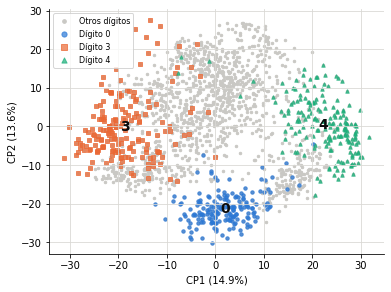

In [7]:
pca2 = PCA(n_components=2).fit(D)
Y2 = pca2.transform(D)
print("Proporción explicada:", pca2.explained_variance_ratio_.round(3), "| suma:", pca2.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(Y2[:, 0], Y2[:, 1], s=6, color="#c9c8c4", label="Otros dígitos")
for dig, color, marca in [(0, AZUL, "o"), (3, NARANJA, "s"), (4, VERDE, "^")]:
    sel = etiqueta == dig
    ax.scatter(Y2[sel, 0], Y2[sel, 1], s=12, color=color, marker=marca, alpha=0.7, label=f"Dígito {dig}")
    cx, cy = Y2[sel].mean(axis=0)
    ax.text(cx, cy, str(dig), fontsize=14, fontweight="bold", color=TINTA, ha="center", va="center")
ax.set_xlabel(f"CP1 ({pca2.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"CP2 ({pca2.explained_variance_ratio_[1]:.1%})")
ax.legend(fontsize=8, markerscale=1.5); plt.show()

### Lea la salida

1. Los dos primeros componentes explican sólo `____` % de la varianza.
2. Aun así, los dígitos `____`, `____` y `____` ocupan zonas distintas del plano. ¿Usó el PCA la etiqueta de cada imagen? `____`.
3. Los puntos grises se enciman mucho porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 28.5 %.
2. El 0, el 3 y el 4. No: el PCA es no supervisado y sólo usa los 64 píxeles; la separación surge de la forma de los dígitos.
3. Con el 28.5 % de la varianza se pierde mucha información, y los dígitos de forma parecida (como el 1 y el 7) necesitan más componentes para distinguirse.

</details>

## 6. ¿Cuántos componentes?

Componentes para el 75%: 11
Componentes para el 90%: 21
Componentes para el 95%: 29
Varianza total: 1202.1 | varianza promedio por píxel: 18.78
Eigenvalores mayores que 1: 47 | mayores que la varianza promedio: 14


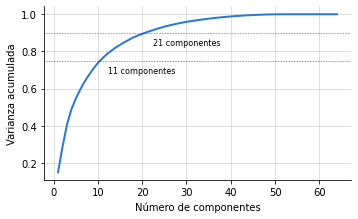

In [8]:
pca_all = PCA().fit(D)
acum = np.cumsum(pca_all.explained_variance_ratio_)
for meta in [0.75, 0.90, 0.95]:
    print(f"Componentes para el {meta:.0%}: {np.argmax(acum >= meta) + 1}")
lam = pca_all.explained_variance_
print("Varianza total:", lam.sum().round(1), "| varianza promedio por píxel:", lam.mean().round(2))
print("Eigenvalores mayores que 1:", (lam > 1).sum(), "| mayores que la varianza promedio:", (lam > lam.mean()).sum())

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(np.arange(1, 65), acum, color=AZUL, lw=2)
for meta in [0.75, 0.90]:
    k = np.argmax(acum >= meta) + 1
    ax.axhline(meta, color=TINTA, lw=0.6, ls=":")
    ax.annotate(f"{k} componentes", (k, meta), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("Número de componentes"); ax.set_ylabel("Varianza acumulada"); plt.show()

### Lea la salida

1. Para explicar el 90 % se necesitan `____` componentes de 64.
2. Con $\mathbf{S}$, la regla "eigenvalor mayor que 1" retendría `____` componentes, pero no tiene sentido porque `____`.
3. La generalización del criterio de Kaiser a $\mathbf{S}$ compara cada eigenvalor con `____`; retiene `____` componentes.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 21.
2. 47. El umbral de 1 depende de las unidades: si las intensidades fueran de 0 a 1, todos los eigenvalores se dividirían entre 256 y ninguno pasaría de 1 (el primero sería 0.70).
3. Con la varianza promedio de las variables, $\operatorname{tr}(\mathbf{S})/p = 18.78$ (con $\mathbf{R}$ esa varianza promedio es 1, y se recupera el criterio usual). Retiene 14 componentes, que explican el 82.1 %.

</details>

## 7. Error común: estandarizar los píxeles

`StandardScaler` divide cada píxel entre su desviación estándar. Con los dígitos eso es un error.

In [9]:
Z = StandardScaler().fit_transform(D)
acum_R = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
print("Componentes para el 90 %:  con S =", np.argmax(acum >= 0.9) + 1, "| con R =", np.argmax(acum_R >= 0.9) + 1)
j = np.argmin(np.where(var_px > 0, var_px, np.inf))
print(f"Píxel {j}: varianza original {var_px[j]:.4f}; después de estandarizar, {Z[:, j].var():.1f}")
print("Valores de ese píxel:", np.unique(D[:, j]), "| imágenes en las que no vale 0:", (D[:, j] > 0).sum())

Componentes para el 90 %:  con S = 21 | con R = 31
Píxel 56: varianza original 0.0006; después de estandarizar, 1.0
Valores de ese píxel: [0. 1.] | imágenes en las que no vale 0: 1


### Lea la salida

1. Con $\mathbf{R}$ se necesitan `____` componentes para el 90 %, contra `____` con $\mathbf{S}$.
2. Al estandarizar, el píxel `____` pasa de varianza `____` a `____`: ahora pesa lo mismo que un píxel del centro, aunque `____`.
3. La regla general no es "siempre estandarizar", sino `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 31 con $\mathbf{R}$ contra 21 con $\mathbf{S}$.
2. El píxel 56 (esquina inferior izquierda) pasa de 0.0006 a 1.0, aunque sólo en una de las 1797 imágenes deja de valer 0. Estandarizar convierte ese ruido en una variable tan importante como las del centro.
3. Estandarizar cuando las variables están en unidades o escalas que no son comparables (como en `PCA_Paises`), y no hacerlo cuando todas se miden en la misma escala y sus diferencias de varianza son información (como aquí).

</details>

## 8. Reconstruir los dígitos con $k$ componentes

Con $k$ componentes cada imagen se resume con $k$ números; `inverse_transform` la regresa a 64 píxeles. La primera fila muestra las imágenes originales.

k =  2: varianza perdida = 71.5%
k = 10: varianza perdida = 26.2%
k = 21: varianza perdida = 9.7%
k = 40: varianza perdida = 1.2%


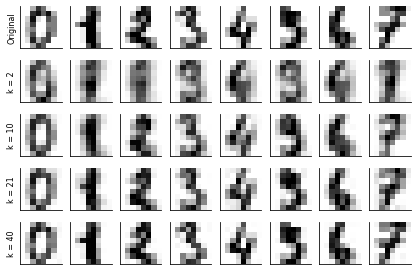

In [10]:
ks = [2, 10, 21, 40]
muestra = D[:8]
fig, axes = plt.subplots(len(ks) + 1, 8, figsize=(7, 4.8), subplot_kw={"xticks": [], "yticks": []})
for i in range(8):
    axes[0, i].imshow(muestra[i].reshape(8, 8), cmap="binary", clim=(0, 16))
axes[0, 0].set_ylabel("Original", fontsize=8)
for fila, k in enumerate(ks, start=1):
    pk = PCA(n_components=k).fit(D)
    rec = pk.inverse_transform(pk.transform(muestra))
    for i in range(8):
        axes[fila, i].imshow(rec[i].reshape(8, 8), cmap="binary", clim=(0, 16))
    axes[fila, 0].set_ylabel(f"k = {k}", fontsize=8)
    print(f"k = {k:2d}: varianza perdida = {1 - pk.explained_variance_ratio_.sum():.1%}")
for ax in axes.flat:
    ax.grid(False)
plt.show()

### Lea la salida

1. Con $k = 2$ se pierde `____` % de la varianza, y los dígitos `____` (se reconocen / no se reconocen).
2. Con $k = 21$ se pierde `____` %, y cada imagen se guarda con `____` números en lugar de 64.
3. La fracción de varianza perdida con $k$ componentes es igual a `____` (escríbala con los eigenvalores).

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 71.5 %; no se reconocen, son manchas.
2. 9.7 %; con 21 números (más la imagen promedio, que es la misma para todas).
3. $(\lambda_{k+1} + \cdots + \lambda_{64})/(\lambda_1 + \cdots + \lambda_{64})$: la suma de los eigenvalores descartados entre la varianza total. Es el mismo resultado de la sección 3, ahora con 64 dimensiones.

</details>

## 9. Autoevaluación

Dos reactivos con el formato del quiz y del examen: elija una opción y complete la justificación. No cuentan para la calificación.

**Reactivo 1.** Con `PCA(n_components=10)` sobre los dígitos, los 10 componentes explican el 73.8 % de la varianza. Una compañera concluye: "se perdieron 54 de los 64 píxeles". ¿Qué es correcto?

- (a) Tiene razón: el PCA conserva los 10 píxeles con más varianza y descarta los 54 restantes, que tienen poca información.
- (b) Se pierde el 26.2 % de la varianza, no píxeles: cada componente combina los 64 píxeles y la reconstrucción devuelve los 64.
- (c) Se pierde el 73.8 % de la información, porque ésa es la proporción que corresponde a los 10 componentes que se conservan.
- (d) No se pierde nada, porque `inverse_transform` recupera exactamente las imágenes originales a partir de las 10 puntuaciones.

*Justificación:* cada componente es una combinación lineal de `____` píxeles. La varianza perdida es `____` %. `inverse_transform` devuelve imágenes de `____` píxeles, pero `____` (iguales / aproximadas) a las originales.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** Cada componente combina los 64 píxeles, así que el PCA no selecciona píxeles (a). Se pierde $1 - 0.738 = 26.2\%$ de la varianza, no el 73.8 % (c). `inverse_transform` devuelve imágenes de 64 píxeles, pero aproximadas: el error es la varianza de los 54 componentes descartados (d).

</details>

**Reactivo 2.** Si las intensidades se reescalan de 0–16 a 0–1 (dividiendo los 64 píxeles entre 16), ¿qué ocurre con el PCA sobre $\mathbf{S}$?

- (a) Cambia todo: las variables quedan en otras unidades, así que hay que estandarizar antes de poder comparar los resultados.
- (b) Las proporciones explicadas se dividen entre 16, porque la varianza de cada uno de los 64 píxeles también se divide entre 16.
- (c) Los eigenvalores se dividen entre 256; los componentes, las proporciones y el número de componentes para el 90 % no cambian.
- (d) Los componentes cambian de dirección, porque los píxeles con más varianza dejan de dominar a los que tienen menos varianza.

*Justificación:* si cada variable se multiplica por $c = 1/16$, $\mathbf{S}$ se multiplica por `____`. Los eigenvectores de $c^2\mathbf{S}$ son `____` que los de $\mathbf{S}$, y sus eigenvalores se multiplican por `____`. Las proporciones `____`. En `PCA_Paises` el problema era distinto, porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(c).** $\mathbf{S}$ se multiplica por $c^2 = 1/256$: los eigenvectores son los mismos y los eigenvalores se dividen entre 256, así que las proporciones no cambian (b) y las direcciones tampoco (d). No hay que estandarizar (a): todas las variables cambian por el mismo factor. En `PCA_Paises` las variables tenían escalas distintas *entre sí* (dólares contra tasas), y eso sí altera el PCA de $\mathbf{S}$.

</details>

## 10. Ejercicio para el alumno

Con `load_breast_cancer()` de `sklearn` (569 tumores y 30 medidas en unidades distintas: radios, áreas, texturas, etcétera):
1. Compare las varianzas de las 30 variables y decida si el PCA debe hacerse con $\mathbf{S}$ o con $\mathbf{R}$. Justifique.
2. Decida cuántos componentes retener con al menos dos criterios.
3. Interprete el CP1 con sus cargas y grafique los dos primeros componentes, distinguiendo tumores benignos y malignos. ¿Usó el PCA esa distinción?

In [11]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer(as_frame=True)
# Su código aquí
cancer.frame.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119,0
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089,0
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088,0
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173,0
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077,0
